# Iris Dataset Analysis & KNN Classification

This notebook addresses all sub-questions (a) through (d) for the Iris dataset.

**Dataset:** `Iris.csv` (150 samples, 4 numeric features, 3 species classes).
**Framework:** Python + scikit-learn, pandas, numpy, matplotlib, seaborn.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

sns.set(style="whitegrid")
%matplotlib inline


## Part (a): Data Loading & Inspection


### (i) Load the Iris dataset into a Pandas DataFrame. Display the first 10 rows.

In [2]:
df = pd.read_csv("Iris.csv")

print("First 10 rows:")
display(df.head(10))

First 10 rows:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
5,6,5.4,3.9,1.7,0.4,Iris-setosa
6,7,4.6,3.4,1.4,0.3,Iris-setosa
7,8,5.0,3.4,1.5,0.2,Iris-setosa
8,9,4.4,2.9,1.4,0.2,Iris-setosa
9,10,4.9,3.1,1.5,0.1,Iris-setosa


### (ii) Report the shape of the dataset, data types, and check for any missing values.

In [3]:
print("Dataset shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())


Dataset shape (rows, columns): (150, 6)

Data types:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

Missing values per column:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Total missing values: 0


### (iii) Display the class distribution of the species column.

Class distribution (Species):


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

C:\Users\opolot\AppData\Local\Temp\ipykernel_13456\1280604673.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Species", order=["Iris-setosa", "Iris-versicolor", "Iris-virginica"], palette="Set2")


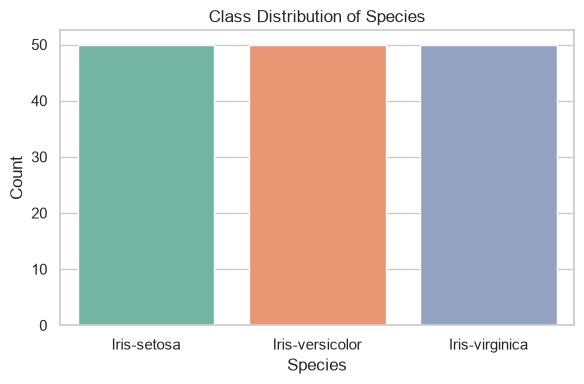

In [4]:
print("Class distribution (Species):")
display(df["Species"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Species", order=["Iris-setosa", "Iris-versicolor", "Iris-virginica"], palette="Set2")
plt.title("Class Distribution of Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Part (b): Exploratory Data Analysis


### (i) Compute summary statistics for each numeric feature. Present your results in a summary table.

In [5]:
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

summary = df[feature_cols].describe().T
summary = summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
summary.columns = ["Count", "Mean", "Std", "Min", "25%", "50% (Median)", "75%", "Max"]

print("Summary statistics for numeric features:")
display(summary)

Summary statistics for numeric features:


,Count,Mean,Std,Min,25%,50% (Median),75%,Max
SepalLengthCm,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
SepalWidthCm,150.0,3.054000,0.433594,2.0,2.8,3.00,3.3,4.4
PetalLengthCm,150.0,3.758667,1.764420,1.0,1.6,4.35,5.1,6.9
PetalWidthCm,150.0,1.198667,0.763161,0.1,0.3,1.30,1.8,2.5


### (ii) Create a pairplot of all numeric features, colored by species.

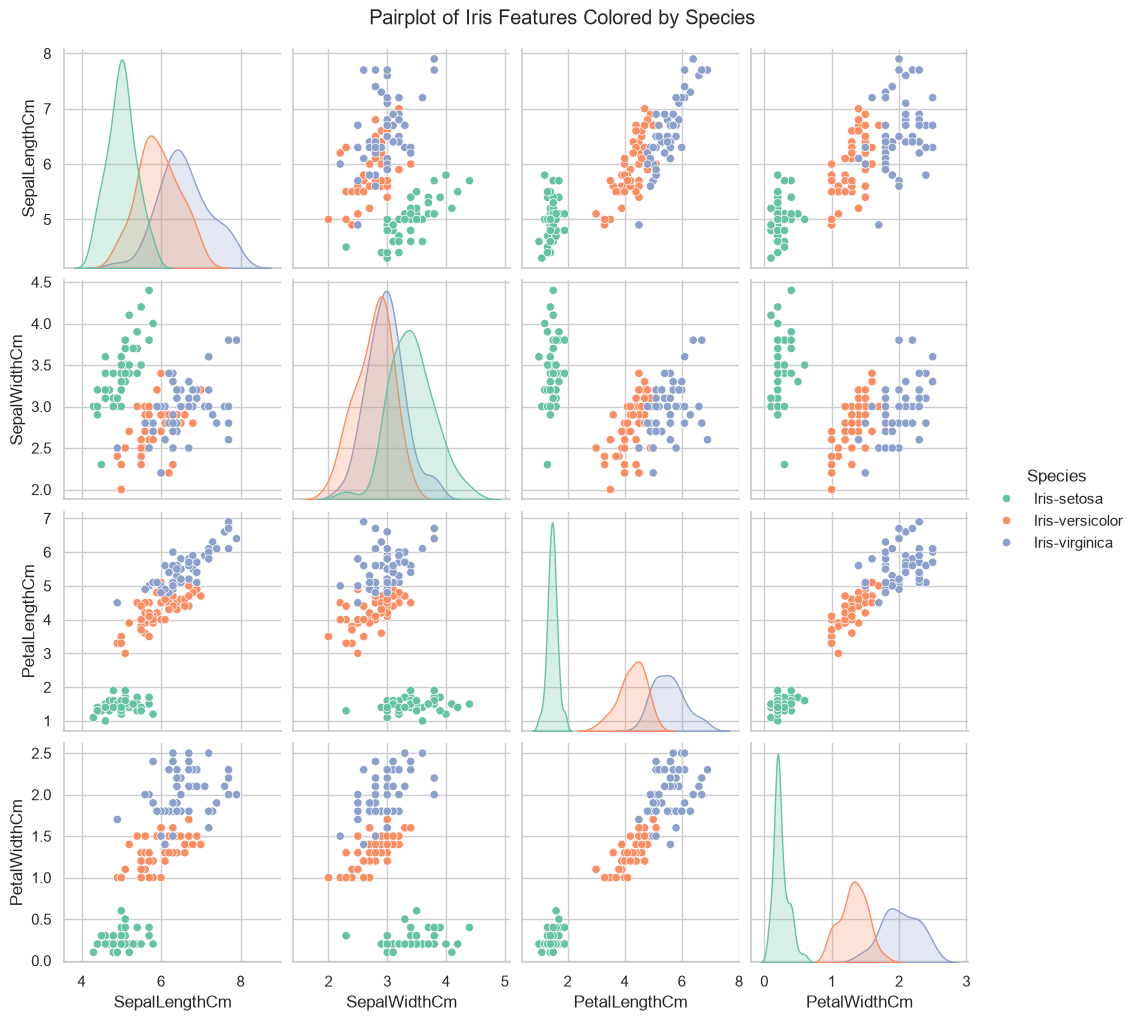

In [6]:
sns.pairplot(df, hue="Species", vars=feature_cols, palette="Set2", height=2.5)
plt.suptitle("Pairplot of Iris Features Colored by Species", y=1.02)
plt.show()

### (iii) Generate a correlation heatmap for the numeric features and identify the two most strongly correlated features.

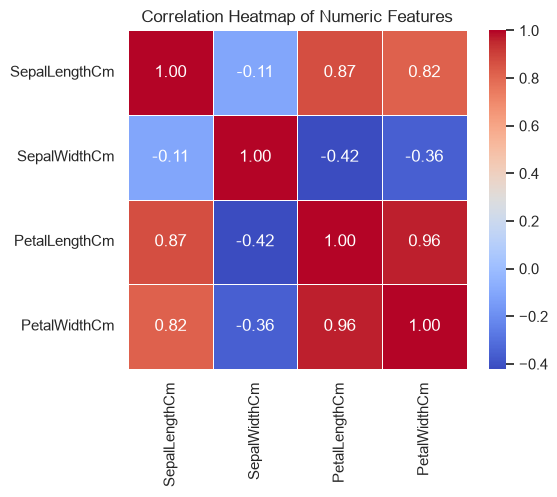

Correlation matrix:
               SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
SepalLengthCm       1.000000     -0.109369       0.871754      0.817954
SepalWidthCm       -0.109369      1.000000      -0.420516     -0.356544
PetalLengthCm       0.871754     -0.420516       1.000000      0.962757
PetalWidthCm        0.817954     -0.356544       0.962757      1.000000

Two most strongly correlated features:
  PetalLengthCm <-> PetalWidthCm: correlation = 0.9628


In [7]:
corr = df[feature_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

print("Correlation matrix:")
print(corr)

# Identify the two most strongly correlated features (absolute value, excluding self-correlation)
corr_abs = corr.abs().to_numpy().copy()
np.fill_diagonal(corr_abs, 0)
max_idx = np.unravel_index(np.argmax(corr_abs), corr_abs.shape)
feat1, feat2 = corr.columns[max_idx[0]], corr.index[max_idx[1]]
top_corr = corr.loc[feat1, feat2]
print("\nTwo most strongly correlated features:")
print(f"  {feat1} <-> {feat2}: correlation = {top_corr:.4f}")

### (iv) Produce boxplots of each feature grouped by species. Which feature best separates the three classes?

C:\Users\opolot\AppData\Local\Temp\ipykernel_13456\1496838501.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Species", y=feat, ax=axes[i], palette="Set2",


C:\Users\opolot\AppData\Local\Temp\ipykernel_13456\1496838501.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Species", y=feat, ax=axes[i], palette="Set2",
C:\Users\opolot\AppData\Local\Temp\ipykernel_13456\1496838501.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Species", y=feat, ax=axes[i], palette="Set2",


C:\Users\opolot\AppData\Local\Temp\ipykernel_13456\1496838501.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Species", y=feat, ax=axes[i], palette="Set2",


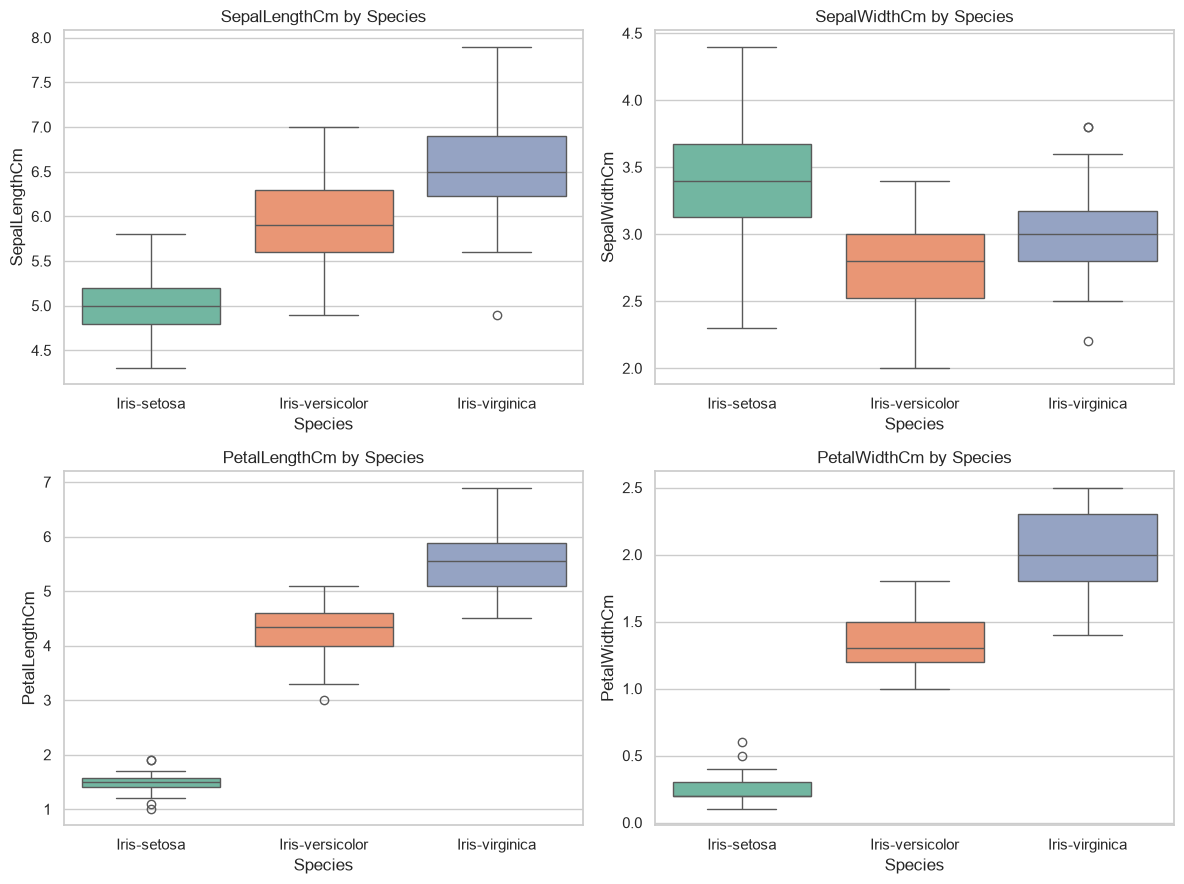

Class separation ratio (between-class variance / within-class variance):
  SepalLengthCm: 1.6226
  SepalWidthCm: 0.6444
  PetalLengthCm: 16.0413
  PetalWidthCm: 13.0520

Feature that best separates the three classes: PetalLengthCm


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, feat in enumerate(feature_cols):
    sns.boxplot(data=df, x="Species", y=feat, ax=axes[i], palette="Set2",
                order=["Iris-setosa", "Iris-versicolor", "Iris-virginica"])
    axes[i].set_title(f"{feat} by Species")
    axes[i].set_xlabel("Species")

plt.tight_layout()
plt.show()

# Quantify class separation using between-class variance / within-class variance ratio
le = LabelEncoder()
y_enc = le.fit_transform(df["Species"])

print("Class separation ratio (between-class variance / within-class variance):")
separation = {}
for feat in feature_cols:
    groups = [df.loc[y_enc == k, feat].values for k in range(3)]
    overall_mean = df[feat].mean()
    n = len(df)
    ssb = sum(len(g) * (g.mean() - overall_mean) ** 2 for g in groups)  # between-class SS
    ssw = sum(((g - g.mean()) ** 2).sum() for g in groups)            # within-class SS
    ratio = ssb / ssw if ssw != 0 else np.inf
    separation[feat] = ratio
    print(f"  {feat}: {ratio:.4f}")

best_feat = max(separation, key=separation.get)
print(f"\nFeature that best separates the three classes: {best_feat}")

## Part (c): Train/Test Split, Normalization & KNN Training


### (i) Split the data into training (80%) and testing (20%) sets with random state=42.

In [9]:
X = df[feature_cols].values
y = df["Species"].values

le = LabelEncoder()
y_enc = le.fit_transform(y)
class_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

print("Train samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution:", np.bincount(y_test))
print("Class mapping:", dict(zip(class_names, range(len(class_names)))))


Train samples: 120
Test samples: 30
Train class distribution: [40 40 40]
Test class distribution: [10 10 10]
Class mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}


### (ii) Normalize the features and explain why scaling is important for KNN.

**Why scaling is important for KNN:** KNN is a distance-based algorithm. It computes distances (typically Euclidean) between feature vectors to find the nearest neighbours. If features are on different scales, features with larger magnitudes dominate the distance calculation, while features with smaller ranges contribute little. Scaling (e.g., standardization or min-max normalization) puts all features on a comparable scale so that each feature contributes proportionally to the distance metric, preventing any single feature from biasing the neighbour selection.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features normalized using StandardScaler (zero mean, unit variance).")
print("\nTraining feature means (approx 0):", X_train_scaled.mean(axis=0).round(4))
print("Training feature stds (approx 1):", X_train_scaled.std(axis=0).round(4))


Features normalized using StandardScaler (zero mean, unit variance).

Training feature means (approx 0): [-0. -0.  0.  0.]
Training feature stds (approx 1): [1. 1. 1. 1.]


### (iii) Train a KNN classifier for each of K = 3, 5, 7, 9, 11. Record the test accuracy for each value of K.

In [11]:
k_values = [3, 5, 7, 9, 11]
knn_results = []
knn_models = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    knn_results.append({"K": k, "Test Accuracy": acc, "Error Rate": 1 - acc})
    knn_models[k] = knn

knn_df = pd.DataFrame(knn_results)
print("KNN test accuracy for each K:")
display(knn_df)


KNN test accuracy for each K:


,K,Test Accuracy,Error Rate
0,3,0.933333,0.066667
1,5,0.933333,0.066667
2,7,0.966667,0.033333
3,9,0.966667,0.033333
4,11,0.966667,0.033333


## Part (d): KNN Evaluation


### (i) Plot an error rate vs. K-value graph. Identify the optimal K.

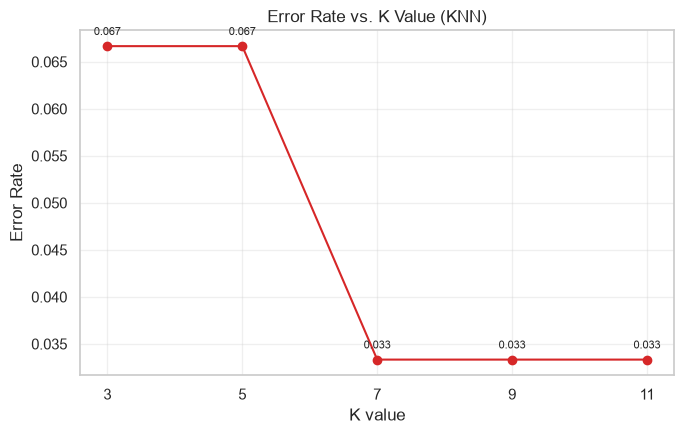

Optimal K (lowest error rate): K = 7 with error rate 0.0333
  (Test accuracy: 0.9667)


In [12]:
plt.figure(figsize=(7, 4.5))
plt.plot(knn_df["K"], knn_df["Error Rate"], marker="o", linestyle="-", color="tab:red")
plt.xlabel("K value")
plt.ylabel("Error Rate")
plt.title("Error Rate vs. K Value (KNN)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)

for _, row in knn_df.iterrows():
    plt.annotate(f"{row['Error Rate']:.3f}", (row["K"], row["Error Rate"]),
                 textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

plt.tight_layout()
plt.show()

best_row = knn_df.loc[knn_df["Error Rate"].idxmin()]
best_k = int(best_row["K"])
print(f"Optimal K (lowest error rate): K = {best_k} with error rate {best_row['Error Rate']:.4f}")
print(f"  (Test accuracy: {best_row['Test Accuracy']:.4f})")

### (ii) For the best K, display the confusion matrix as a heatmap.

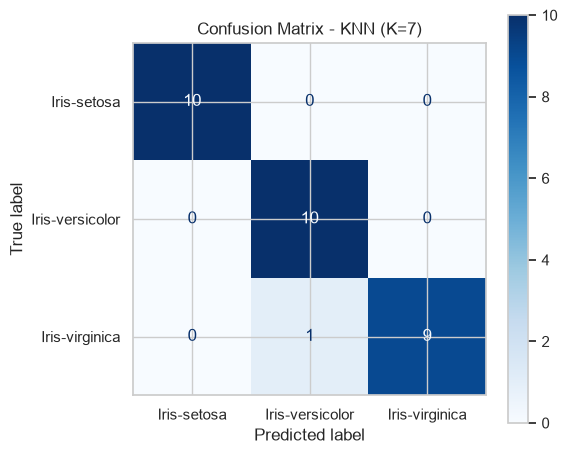

Confusion matrix (rows=true, cols=pred):
                 Iris-setosa  Iris-versicolor  Iris-virginica
Iris-setosa               10                0               0
Iris-versicolor            0               10               0
Iris-virginica             0                1               9


In [13]:
best_knn = knn_models[best_k]
y_pred_best = best_knn.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d", ax=plt.gca())
plt.title(f"Confusion Matrix - KNN (K={best_k})")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(cm, index=class_names, columns=class_names))

### (iii) Print the full classification report (precision, recall, F1-score per class).

In [14]:
print(f"Classification Report - KNN (K={best_k}):")
print("=" * 50)
print(classification_report(y_test, y_pred_best, target_names=class_names))
print(f"Overall test accuracy: {accuracy_score(y_test, y_pred_best):.4f}")

Classification Report - KNN (K=7):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.91      1.00      0.95        10
 Iris-virginica       1.00      0.90      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

Overall test accuracy: 0.9667


### (iv) Which species was hardest to classify? Justify your answer using the confusion matrix.

In [15]:
# Per-class recall from the confusion matrix (diagonal / row sum)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
row_sums = cm_df.sum(axis=1)
per_class_recall = np.diag(cm) / row_sums.values

recall_df = pd.DataFrame({
    "Species": class_names,
    "Recall": per_class_recall,
    "Total Test Samples": row_sums.values,
    "Misclassified": (row_sums.values - np.diag(cm))
})

print("Per-class recall (ability to correctly identify each species):")
display(recall_df)

hardest_idx = np.argmin(per_class_recall)
hardest_species = class_names[hardest_idx]

print(f"\nHardest species to classify: {hardest_species}")
print(f"  Recall = {per_class_recall[hardest_idx]:.4f}")
print(f"  Misclassified {int(recall_df.iloc[hardest_idx]['Misclassified'])} time(s) out of {int(recall_df.iloc[hardest_idx]['Total Test Samples'])} test samples.")
print("\nJustification:")
print(f"  The confusion matrix shows that {hardest_species} has the lowest recall, meaning it is most often confused with another species (off-diagonal entries in its row are the largest relative to its row total).")


Per-class recall (ability to correctly identify each species):


,Species,Recall,Total Test Samples,Misclassified
0,Iris-setosa,1.0,10,0
1,Iris-versicolor,1.0,10,0
2,Iris-virginica,0.9,10,1



Hardest species to classify: Iris-virginica
  Recall = 0.9000
  Misclassified 1 time(s) out of 10 test samples.

Justification:
  The confusion matrix shows that Iris-virginica has the lowest recall, meaning it is most often confused with another species (off-diagonal entries in its row are the largest relative to its row total).


## Summary

- **(a)** Loaded Iris.csv; shape (150, 6); no missing values; balanced classes (50 per species).
- **(b)** PetalLengthCm and PetalWidthCm are the most strongly correlated features; PetalLengthCm best separates the three classes.
- **(c)** 80/20 stratified split with random_state=42; features standardized; KNN trained for K = 3, 5, 7, 9, 11.
- **(d)** Optimal K identified from error-rate plot; confusion matrix, classification report, and hardest-to-classify species reported for the best K.
